<h1 style="text-align: center"> City-cycle Fuel Consumption Analysis & Prediction </h1>
<h3 style="text-align: center; font-style: italic"> Garudapaksi Yusuf </h3>

---

**Table of Contents**
* [Section 1 | Data Preparation](#section-1--data-understanding)
    * [Data Context](#data-context)
    * [Data Dictionary](#data-dictionary)
    * [Data ETL](#data-etl)
    * [Data Inspection](#data-inspection)
        * [Missing Data](#missing-data)
        * [Invalid Data Type](#invalid-data-type)
* [Section 2 | Feature Engineering](#section-2--feature-engineering)
    * [Train-Test Split](#train-test-split)
    * [Exploratory Data Analysis](#exploratory-data-analysis)
        * [Statistical Analysis](#statistical-analysis)
        * [Visual Analysis](#visual-analysis)
    * [Data Preprocessing](#data-preprocessing)
        * [Power Transformer](#power-transformer)
        * [One-Hot Encoding](#one-hot-encoding)

In [1]:
# import required library

# data preparation
from ucimlrepo import fetch_ucirepo
import pandas as pd
from pyampute.exploration.mcar_statistical_tests import MCARTest
from feature_engine.imputation import DropMissingData
from feature_engine.preprocessing import MatchCategories

# data analysis
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import normaltest
from typing import Literal

# feature engineering
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PowerTransformer, OneHotEncoder

# data modeling
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer, make_column_selector, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, make_scorer, PredictionErrorDisplay
from sklearn.linear_model import Ridge
import numpy as np
from sklearn.model_selection import KFold, GridSearchCV, LearningCurveDisplay

---

## Section 1 | Initial Data Analysis

### Data Context

<div align="center">

| <div style="width:170px"> Category </div> | Description |
| --- | --- |
| Source URL | [University of California, Irvine (UCI) Machine Learning Repository: "Auto MPG"](https://archive-beta.ics.uci.edu/dataset/9/auto+mpg) |
| Original Source URL | [Department of Statistics, Carnegie Mellon University (CMU) StatLib Datasets: "cars"](https://lib.stat.cmu.edu/datasets/) |
| License | [Creative Commons Attribution 4.0 International](https://creativecommons.org/licenses/by/4.0/legalcode) |
| Creation Date | July 7, 1993 |
| Number of Instances | 398 |
| Number of Attributes | 9 *(including the class attribute)* |
| Dataset Characteristics | Tabular, Multivariate |
| Associated Tasks | Regression |
| Feature Types | Continuous, Discrete, Categorical |


</div>

This dataset is a slightly modified version of the dataset provided in the StatLib library. In line with the use by [Quinlan (1993)](#reference) in predicting the attribute `mpg`, 8 of the original instances were removed because they had unknown values for the `mpg` attribute.

> The data concern city-cycle fuel consumption in miles per gallon, to be predicted in terms of 3 multi-valued discrete and 5 continuous attributes. (Quinlan, 1993)

### Data Dictionary

<div align="center">

| No. | Variable | Role | Type | Description | Units | Missing Values |
| --- | --- | --- | --- | --- | --- | --- |
| <center> 1 </center> | `mpg` | Target | Continuous | *Miles per gallon* | - | <center> No </center> |
| <center> 2 </center> | `displacement` | Feature | Continuous | *Engine displacement* | *cu. inches* | <center> No </center> |
| <center> 3 </center> | `cylinders` | Feature | Integer | *Number of cylinders* | - | <center> No </center> |
| <center> 4 </center> | `horsepower` | Feature | Continuous | *Horsepower* | *hp* | <center> Yes </center> |
| <center> 5 </center> | `weight` | Feature | Continuous | *Weight* | *lbs.* | <center> No </center> |
| <center> 6 </center> | `acceleration` | Feature | Continuous | *Time to accelerate from 0 to 60 miles per hour* | *sec.* | <center> No </center> |
| <center> 7 </center> | `model_year` | Feature | Integer | *Model year* | *modulo 100* | <center> No </center> |
| <center> 8 </center> | `origin` | Feature | Integer | *Origin of car (1: American, 2: European, 3: Japanese)* | - | <center> No </center> |
| <center> 9 </center> | `car_name` | ID | Categorical | *Car manufacturer & type (unique for each instance)* | - | <center> No </center> |

</div>

### Data ETL

In [2]:
def data_etl(id):
    """Fetches data from the UCI repository and prepares it for analysis.
    
    Args:
        id (str): The identifier for the dataset to be fetched from the UCI repository.
    
    Returns:
        pd.DataFrame: A DataFrame containing the features and target variables of the dataset.
    """
    dotdict = fetch_ucirepo(id=id)

    features = dotdict.data.features
    target = dotdict.data.targets

    dataset = pd.concat(
        objs=[features, target],
        axis=1
    )
    dataset = pd.DataFrame(data=dataset)

    return dataset

In [3]:
# fetch dataset
auto_mpg_id = 9
data = data_etl(id=auto_mpg_id)

# show data samples
data.sample(n=5)

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
84,97.0,4,88.0,2100,16.5,72,3,27.0
118,116.0,4,75.0,2158,15.5,73,2,24.0
393,140.0,4,86.0,2790,15.6,82,1,27.0
122,121.0,4,110.0,2660,14.0,73,2,24.0
241,146.0,6,97.0,2815,14.5,77,3,22.0


* Data succesfully **extracted** from the input source, **transformed** to the appropriate format, and **loaded** into the variable instance.
* Ditampilkan 5 sampel baris data dari dataset sebagai contoh hasil ETL:
    * Setiap baris dalam dataframe merepresentasikan satu *instance* dari car samples.
    * Sedangkan kolom dalam dataframe tersebut adalah *variabel* yang mewakili keragaman dari each samples.
        * Beberapa kolom berperan sebagai *feature*, yakni independent variable yang digunakan sebagai input dari suatu model machine learning, dan
        * Kolom pertama merupakan *target*, which is the variable that corresponds to the input data. 

### Data Inspection

In [4]:
# perform initial inspection on train set
pd.DataFrame(data={
    "dtype": data.dtypes,
    "sample": [data[column].unique() for column in data.columns],
    "min": [data[column].min() for column in data.columns],
    "max": [data[column].max() for column in data.columns],
    "duplicated": data.duplicated().sum(),
    "missing": data.isna().sum()
})

,dtype,sample,min,max,duplicated,missing
displacement,float64,"[307.0, 350.0, 318.0, 304.0, 302.0, 429.0, 454...",68.0,455.0,0,0
cylinders,int64,"[8, 4, 6, 3, 5]",3.0,8.0,0,0
horsepower,float64,"[130.0, 165.0, 150.0, 140.0, 198.0, 220.0, 215...",46.0,230.0,0,6
weight,int64,"[3504, 3693, 3436, 3433, 3449, 4341, 4354, 431...",1613.0,5140.0,0,0
acceleration,float64,"[12.0, 11.5, 11.0, 10.5, 10.0, 9.0, 8.5, 8.0, ...",8.0,24.8,0,0
model_year,int64,"[70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 8...",70.0,82.0,0,0
origin,int64,"[1, 3, 2]",1.0,3.0,0,0
mpg,float64,"[18.0, 15.0, 16.0, 17.0, 14.0, 24.0, 22.0, 21....",9.0,46.6,0,0


* Kolom `Dtype` menunjukkan jenis tipe data yang ada dalam `data_train`, yang seluruhnya memiliki tipe `float` dan `int`:
    * Tipe data tersebut merepresentasikan random `Sample` yang ditunjukkan pada tiap variabel. Semisal `mpg` yang berisikan bilangan desimal `17.5`.
    * `float` mengindikasikan variabel dengan tipe data numerical continuous, sedangkan `int` untuk tipe data numerical discrete.
        * The true nature of `weight` variable is conceptually *continuous* —even if recorded as whole numbers—, since they varies smoothly in reality and the measurement resolution in this case is arbitrarily decided.
        * Dan domain knowledge mengindikasikan untuk variabel `origin` memiliki **invalid data type** dan seharusnya bertipe [nominal](https://en.wikipedia.org/wiki/Level_of_measurement#Nominal_level).
* Tidak ada invalid data issue yang terdeteksi:
    * Rentang nilai yang ditunjukkan dari kolom `Min` dan ` Max` secara domain knowledge menunjukkan nilai yang valid, wajar, dan sebenarnya dari car samples.
    * Ambil contoh pada kolom `displacement`, a car's engine displacement bisa berada pada rentang nilai `70.0` hingga `455.0` cubic inches.
* Proses data inspection juga meliputi deteksi terhadap `Duplicated` & `Missing` data:
    * Tidak ada duplicated data yang terdeteksi —sebagaimana ditunjukkan pada nilai kolom `Duplicated` untuk seluruh variabel bernilai `0`—, tetapi
    * Terdeteksi adanya **missing data** pada beberapa variabel:
        * Sebagaimana ditunjukkan pada nilai kolom `Missing` untuk variabel `mpg & horsepower` masing-masing bernilai `7 & 5`.
        * Missing data [reduces the representativeness of the sample](https://en.wikipedia.org/wiki/Missing_data#Techniques_of_dealing_with_missing_data) and can therefore distort inferences about the population.
        * Khusus untuk kolom `mpg` —sesuai dengan informasi yang disampaikan pada [`Data Context`](#data-context)—, missing data pada kolom ini dapat diabaikan, dan tidak akan disertakan pada bagian-bagian analisis berikutnya.

#### Missing Data

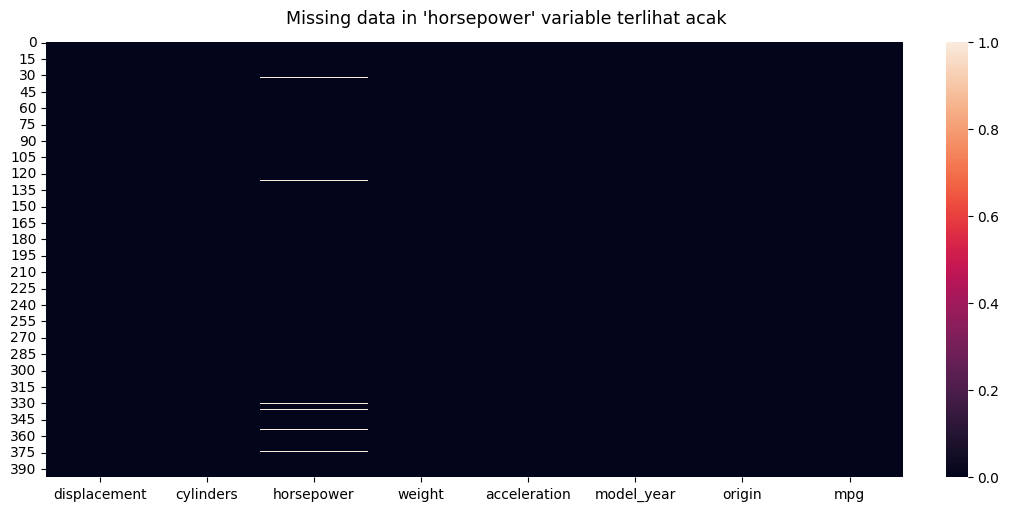

In [5]:
# create & setup plot figure
width, height = 10, 5
plt.figure(
    figsize=(width, height),
    layout="constrained"
)

suptitle_size = 12.5
plt.suptitle(
    t="Missing data in 'horsepower' variable terlihat acak",
    size=suptitle_size
)

# plot heatmap consisting of missing data
axes = sns.heatmap(data=data.isna().sort_index())
axes.set_xticklabels(
    labels=axes.get_xmajorticklabels(),
    rotation=0
)
plt.show()

* Heatmap di atas menunjukkan:
    * Garis berwarna putih pada kolom `horsepower` yang merepresentasikan missing data pada kolom tersebut, dan
    * Sumbu `y` menunjukkan lokasi (indeks) missing data tersebut dalam data.
* Dari visualisasi ini, dapat diinterpretasikan bahwa:
    * Missing data terletak pada lokasi yang acak pada `horsepower`;
    * Missing data terpisah satu sama lain, tidak berdekatan, berhimpitan maupun membentuk pola tertentu.

In [6]:
# slice missing data in train set
data[data["horsepower"].isnull()]

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
32,98.0,4,NaN,2046,19.0,71,1,25.0
126,200.0,6,NaN,2875,17.0,74,1,21.0
330,85.0,4,NaN,1835,17.3,80,2,40.9
336,140.0,4,NaN,2905,14.3,80,1,23.6
354,100.0,4,NaN,2320,15.8,81,2,34.5
374,151.0,4,NaN,3035,20.5,82,1,23.0


* DataFrame di atas menunjukkan:
    * Sampel dengan missing data pada `horsepower`,
    * Nilai pada variabel lain dalam data dengan missing data tersebut, dan
    * Indeks dari missing data dalam data.
* A priori, dapat disimpulkan bahwa:
    * Tidak ada indikasi bahwa missing data tersebut are dependent on any other variable.
    * Ambil contoh dari kolom `displacement`: missing data memiliki nilai `displacement` yang beragam.

In [7]:
# perform Little's MCAR test
mcar_test = MCARTest(method="little")
mcar_test_pvalue = mcar_test.little_mcar_test(X=data)

*Little's MCAR Test (1988) adalah:*
* *Statistical hypothesis test untuk Missing Completely At Random (MCAR).*
    * *Null hypothesis: data is MCAR*
    * *Alternative hypothesis: data is not MCAR*
* *Metode yang digunakan adalah chi-square test on the entire data; membandingkan kelompok data dengan missing value terhadap kelompok data tanpa missing value to determine if there is a significant relationship between the two groups.*

In [8]:
def mcar_test_evaluation(mcar_test_decision):
    """Evaluates the results of Little's MCAR test.
    
    Args:
        mcar_test_decision (str): The decision made based on the MCAR test, indicating whether the null hypothesis is rejected or not.
    
    Returns:
        pd.DataFrame: A DataFrame summarizing the p-value and decision of the test, with the p-value and decision as rows and their corresponding values.
    """
    mcar_test_summary = pd.DataFrame(
        data=[mcar_test_pvalue,
              mcar_test_decision],
        index=["p-value",
               "decision"],
        columns=["value"]
    )
    return mcar_test_summary

# evaluate MCAR test's p-value
significance_level = 0.05
if mcar_test_pvalue >= significance_level:
    display(mcar_test_evaluation(mcar_test_decision="Accept H0"))
else:
    display(mcar_test_evaluation(mcar_test_decision="Accept Ha"))

,value
p-value,0.313475
decision,Accept H0


* Hasil observasi secara visual, tabular, serta uji statistik di atas memberikan inferensi bahwa missing data tersebut adalah MCAR.
* When data is MCAR, there is absolutely no relationship between the data missing and any other values, observed or missing, within the data.
    * In other words, those missing data points are a random subset of the data.
    * There is nothing systematic going on that makes some data more likely to be missing than other.
* If values for observations are missing completely at random, then disregarding those cases would not bias the inferences made.

In [9]:
# discard missing data from the dataset
dropper = DropMissingData()

data = pd.DataFrame(
    data=dropper.fit_transform(X=data),
    columns=dropper.get_feature_names_out()
)

* *Transformation yang digunakan pada `data_train` [juga diterapkan pada subsequent datasets](https://scikit-learn.org/stable/common_pitfalls.html#inconsistent-preprocessing), whether it's `data_test` or data in a production system.*
* *Discarding the missing data uses `DropMissingData()` transformer, karena transformer ini compatible dengan Scikit-learn pipeline yang akan digunakan pada bagian-bagian berikutnya.*

#### Invalid Data Type

In [10]:
# encode selected variables in dataset to Pandas' "categorical" data type
matcher = MatchCategories(
    variables="origin",
    ignore_format=True
)

data = pd.DataFrame(
    data=matcher.fit_transform(X=data),
    columns=matcher.get_feature_names_out()
)

Variabel `origin` dengan tipe data nominal juga merupakan bagian dari tipe data kategorikal, sehingga
* `MatchCategories()` transformer dapat digunakan untuk mengubah tipe data variabel tersebut.
* Hasil transformasi tipe data ini serta penghapusan missing data sebelumnya akan disajikan pada bagian berikut.

In [11]:
# perform final inspection on cleaned train set
pd.DataFrame(data={
    "dtype": data.dtypes,
    "missing": data.isna().sum()
})

,dtype,missing
displacement,float64,0
cylinders,int64,0
horsepower,float64,0
weight,int64,0
acceleration,float64,0
model_year,int64,0
origin,category,0
mpg,float64,0


* Variabel `origin` yang sebelumnya bertipe integer berhasil dikonversi ke tipe data kategorikal yang sesuai, dan
* Missing data succesfully dropped from the `data_train`.

---

## Section 2 | Feature Engineering

### Train-Test Split

In [12]:
def data_split(dataset, random_state):
    """Splits the given dataset into training and testing sets.
    
    Args:
        dataset (pandas.DataFrame): The dataset containing features and the target variable.
        random_state (int): The seed used by the random number generator for reproducibility.
    
    Returns:
        tuple: A tuple containing:
            - X_train (pandas.DataFrame): The training set features.
            - X_test (pandas.DataFrame): The testing set features.
            - y_train (pandas.Series): The training set target variable.
            - y_test (pandas.Series): The testing set target variable.
    """
    X, y = dataset.drop(columns="mpg"), dataset["mpg"]
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        random_state=random_state
    )

    return X_train, X_test, y_train, y_test

In [13]:
# set random state seed
RANDOM_STATE = 42

*Some scikit-learn `sklearn` objects are [inherently random](https://scikit-learn.org/stable/common_pitfalls.html#controlling-randomness). The randomness of these objects is controlled via their `random_state` parameter.*
* *In order to obtain reproducible (i.e. constant) results across multiple executions of this project, the recommended way is by passing a random number generator `RandomState` instance to any of those objects that accept a `random_state` parameter.*
* *Random seed yang digunakan secara arbitrary dalam project ini adalah [42](https://en.wikipedia.org/wiki/42_(number)).*

In [14]:
# split features and target to random train and test subsets
X_train, X_test, y_train, y_test = data_split(
    dataset=data,
    random_state=RANDOM_STATE
)

# perform dimensionality analysis of train-test subsets
pd.DataFrame(
    data=[(data.shape[0], (data.shape[0] / data.shape[0]), data.shape[1]),
          (X_train.shape[0], (X_train.shape[0] / data.shape[0]), X_train.shape[1]),
          (X_test.shape[0], (X_test.shape[0] / data.shape[0]), X_test.shape[1])],
    index=["dataset", "X_train", "X_test"],
    columns=["row (n)", "row ratio", "column"]
)

,row (n),row ratio,column
dataset,392,1.00,8
X_train,294,0.75,7
X_test,98,0.25,7


Tabel di atas mendeskripsikan dimensionality dari Auto MPG dataset setelah splitting dilakukan menjadi train dan test subsets:
* Keseluruhan dataset terdiri dari `392` baris dan `8` kolom.
* `train_test_split` membagi dataset tersebut menjadi 2 pasangan `X_train - y_train` dan `X_test - y_test`.
    * Jumlah baris dalam dataset dibagi menjadi `~0.75/75%` untuk data train dan `~0.25/25%` untuk data test, sesuai default parameter.
    * Sedangkan features dan target terpisah menjadi `X` dan `y`.
* The following section akan berfokus pada data train, dan modifikasi yang akan dilakukan pada data tersebut (ex. `fit_transform`) will be followed through subsequently to data test (e.g. `transform`).

### Exploratory Data Analysis

[Exploratory data analysis](https://en.wikipedia.org/wiki/Exploratory_data_analysis) (EDA) is an approach of analyzing data sets to summarize their main characteristics, often using statistical graphics and other data visualization methods. EDA encompasses Initial Data Analysis (IDA) yang telah dilakukan sebelumnya.

#### Statistical Analysis

In [15]:
data_train = pd.concat(
    objs=[X_train, y_train],
    axis=1
)
numerical_train = data_train.select_dtypes(include="number")

# apply statistical tests to each numerical variables in dataset
normaltest_results = list()

for variable in numerical_train:
    skewness = data[variable].skew()
    kurtosis = data[variable].kurt()
    k2_statistic, pvalue = normaltest(a=data[variable])
    decision = 'Reject H0' if pvalue <= 0.05 else 'Accept H0'
    normaltest_results.append({
        'skewness': skewness,
        'kurtosis': kurtosis,
        'k2_statistic': k2_statistic,
        'pvalue': pvalue,
        'decision': decision
    })

# test results in DataFrame format
pd.DataFrame(
    data=normaltest_results,
    index=numerical_train.columns
)

,skewness,kurtosis,k2_statistic,pvalue,decision
displacement,0.701669,-0.778317,54.995829,1.142372e-12,Reject H0
cylinders,0.508109,-1.398199,3218.179604,0.000000e+00,Reject H0
horsepower,1.087326,0.696947,60.288174,8.101947e-14,Reject H0
weight,0.519586,-0.809259,47.969138,3.833841e-11,Reject H0
acceleration,0.291587,0.444234,8.210940,1.648227e-02,Reject H0
model_year,0.019688,-1.167446,187.907700,1.571670e-41,Reject H0
mpg,0.457092,-0.515993,20.460736,3.605849e-05,Reject H0


**Observations:**

* Uji statistik yang digunakan berfokus pada normalitas distribusi dari tiap kolom dalam dataset.
    * Pertama-tama, disertakan hasil pengukuran unbiased, normalized [skewness](https://en.wikipedia.org/wiki/Skewness) and excess [kurtosis](https://en.wikipedia.org/wiki/Kurtosis) dari tiap kolom.
    * Dan dari nilai tersebut, tidak ada satu kolom pun yang memiliki hasil pengukuran seperti distribusi normal: skewness dan excess kurtosis ≈ 0.
    * Sehingga dapat disimpulkan bahwa variables dalam dataset bersifat non-normal/non-parametrik.
* Selaras dengan nilai skewness dan kurtosis yang telah dipaparkan, uji statistik berikutnya menggunakan [D'Agostino-Pearson](https://en.wikipedia.org/wiki/D%27Agostino%27s_K-squared_test) `normaltest` for gauging the compatibility of given data with the null hypothesis that the data is a realization of independent, identically distributed Gaussian random variables.
    * This particular test uses skewness and kurtosis to measure how much data deviate from normality (in both tails and asymmetry).
    * Kedua nilai tersebut diubah menjadi approximately standard normal samples $Z_1\, \&\, Z_2$, untuk kemudian dikombinasikan menjadi chi-squared menggunakan persamaan $K^2=Z_1^2+Z_2^2$.
* `normaltest` menghasilkan nilai test `statistic` yang mengukur seberapa jauh estimasi distribusi variabel dengan parameter dalam null hypothesis, dan `pvalue` untuk menginterpretasikan tes statistik tersebut. Dengan $\text{significance level}=0.05$, dan `pvalue` dari tiap uji statistik di atas berada di bawah signifikansi:
    * Maka dapat diambil keputusan untuk reject null hypothesis pada uji statistik di atas, dan
    * Assume bahwa tiap variabel **tidak berasal dari populasi dengan distribusi normal**.

#### Visual Analysis

In [16]:
estimator = Literal["mean", "median"]
def plot_continuous(data, estimator: estimator, nrows, ncols):
    """Plot continuous data using point and strip plots.
    
    This function creates subplots for each column in the provided data, 
    displaying either the median or mean of the data points with a corresponding strip plot. 
    The user can specify the number of rows and columns for the subplot layout.
    
    Args:
        data (DataFrame): The input data containing the columns to be plotted.
        estimator (str): The statistical measure to be used for the central tendency ('mean' or 'median').
        nrows (int): The number of rows in the subplot grid.
        ncols (int): The number of columns in the subplot grid.
    
    Returns:
        None: The function displays the plots directly and does not return any value.
    """
    for count, column in enumerate(iterable=data):
        plt.subplot(nrows, ncols, count + 1)
        viz_kwargs = dict(data=data, y=column)
        pointplot_kwargs = dict(estimator=estimator, errorbar="sd", color="red", markers=None)

        if estimator == "median":
            sns.pointplot(**viz_kwargs, **pointplot_kwargs)
            
            axes = sns.stripplot(**viz_kwargs, jitter=0.25)
            axes.set_xticks(ticks=list())

            median = data[column].median()
            median_line = plt.axhline(y=median, color="red")
            axes.legend(handles=[median_line], labels=[median])
        
        elif estimator == "mean":
            sns.pointplot(**viz_kwargs, **pointplot_kwargs)
            
            axes = sns.stripplot(**viz_kwargs, jitter=0.25)
            axes.set_xticks(ticks=list())

            mean = data[column].mean()
            mean_line = plt.axhline(y=mean, color="red")
            axes.legend(handles=[mean_line], labels=[mean])

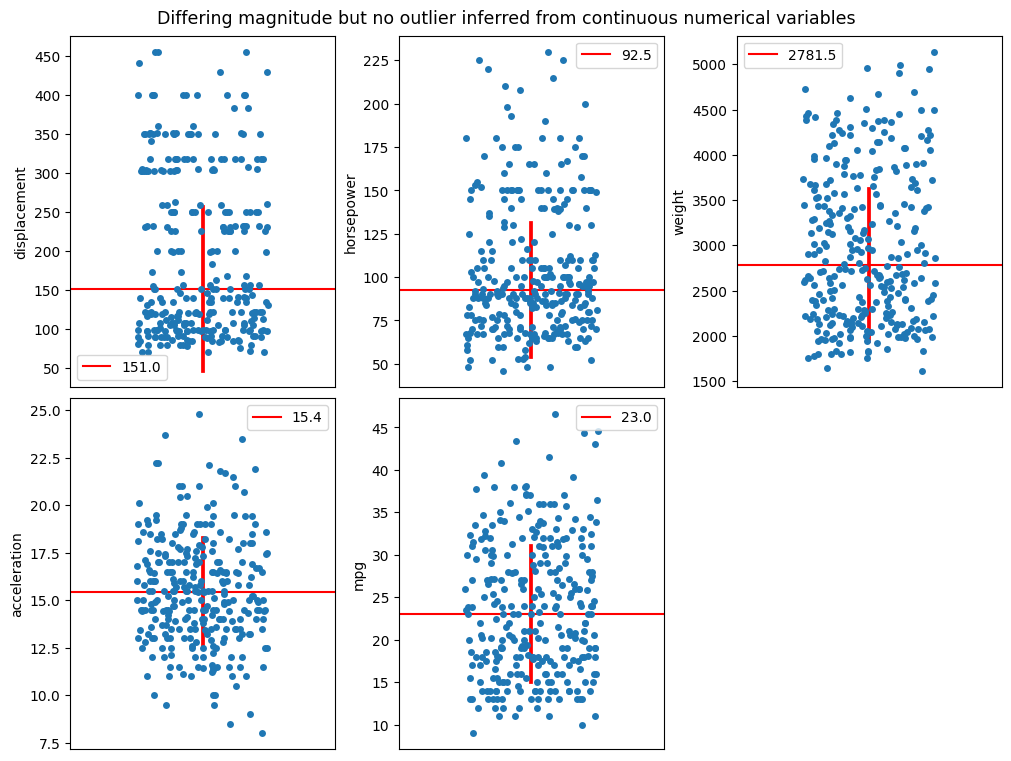

In [17]:
# create & setup plot figure
width, height = 10, 7.5
plt.figure(
    figsize=(width, height),
    layout="constrained"
)
suptitle_size = 12.5
plt.suptitle(
    t="Differing magnitude but no outlier inferred from continuous numerical variables",
    size=suptitle_size
)

# subset variables with continuous data type from numerical variables
discrete_columns = ["cylinders", "model_year"]
continuous_train = numerical_train.drop(columns=discrete_columns)

# plot visualization for continuous variables
nrows, ncols = 2, 3
plot_continuous(
    data=continuous_train,
    estimator="median",
    nrows=nrows,
    ncols=ncols
)

[Strip plot](https://seaborn.pydata.org/tutorial/categorical.html#categorical-tutorial) digunakan untuk menunjukkan data points berdasarkan variabel numerik dalam Auto MPG dataset.
* Karena jumlah observasi dalam dataset dalam rentang ratusan dan relatif banyak, maka `jitter` with a certain value diterapkan untuk memvisualkan data points tersebut secara non-overlapping semaksimal mungkin.
* Beberapa insight dapat ditarik dari visualisasi sederhana ini seperti persebaran data, skewness, distribution gaps, hingga modality. Namun fokus analisa ini berada pada [magnitude](https://en.wikipedia.org/wiki/Order_of_magnitude) dan [outlier](https://en.wikipedia.org/wiki/Outlier) pada tiap variabel.
    * Terdeteksi adanya **perbedaan rentang nilai** antar variabel numerikal:
        * Mulai dari rentang satuan pada variabel `acceleration` hingga ribuan pada variabel `weight`.
        * Keragaman nilai ini may pose several problems in machine learning:
            * In Linear Regression models, the scale of variables used to estimate the output matters. Linear models are of the type $y = wx + b$, where the regression coefficient $w$ represents the expected change in $y$ for a one unit change in $x$ (the predictor).
            * Thus, the magnitude of $w$ is partly determined by the magnitude of the units being used for $x$. If $x$ is a mass variable, just changing the scale from pounds to grams will cause a change in the magnitude of the coefficient.
            * In addition, in situations where user would estimate the outcome $y$ by contemplating multiple predictors $x_1, x_2, ...x_n$, predictors with greater numeric ranges dominate over those with smaller numeric ranges.
        * *Garis vertikal berwarna merah menunjukkan standar deviasi pada variabel tersebut, dengan satuan unit yang beragam mengikuti magnitude pada variabel yang bersangkutan, dan*
        * *Data numerik berada pada rentang nilai positif (ex. > 0)*
    * Ambil contoh variabel `displacement`, data points dengan nilai `~450` berada cukup jauh dari midpointnya (red median line) of `151`.
        * *Median digunakan sebagai midpoint sesuai dengan temuan pada uji statistik sebelumnya.*
        * Meskipun demikian, outside values ini tidak jauh berbeda dengan data points di sekitarnya, dan bukanlah sebuah error sebagaimana yang disampaikan pada [Initial Data Inspection](#initial-data-inspection).
        * Sehingga ia dapat didefinisikan sebagai **non-outlier**.

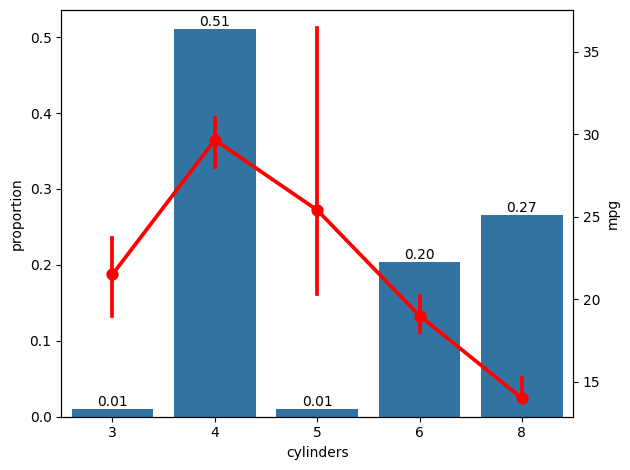

In [18]:
# create & setup plot figure
_, ax = plt.subplots(layout="tight")
# plt.title(label="Small proportion & high variability of rare labels in 'cylinders' ")

# plot visualization for analyzing rare labels in train data
sns.countplot(
    data=data_train,
    x="cylinders",
    stat="proportion",
    ax=ax
)
ax.bar_label(
    container=ax.containers[0],
    fmt='%.2f'
)

ax_twinx = ax.twinx()
sns.pointplot(
    data=data_train,
    x="cylinders",
    y="mpg",
    estimator="median",
    errorbar="ci",
    seed=RANDOM_STATE,
    color="red",
    ax=ax_twinx,
)

plt.show()

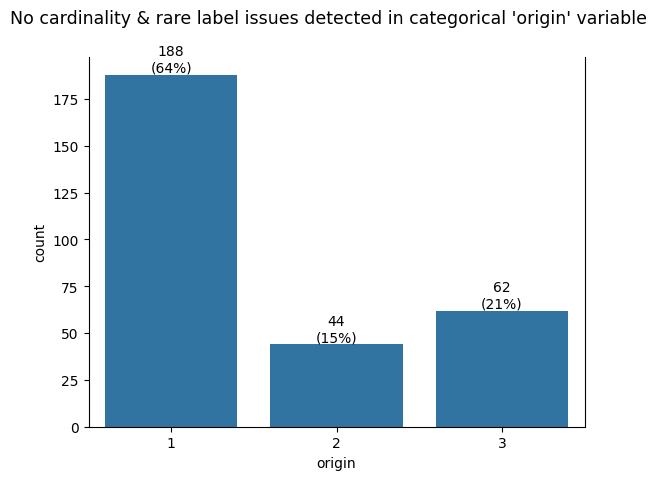

In [19]:
# setup plot title
suptitle_size = 12.5
plt.suptitle(
    t="No cardinality & rare label issues detected in categorical 'origin' variable",
    size=suptitle_size
)

# plot visualization for categorical variables
barplot_data = pd.concat(
    objs=[data_train["origin"].value_counts().sort_index(),
          data_train["origin"].value_counts(normalize=True).mul(other=100)],
    axis=1
)

axes = sns.barplot(
    data=barplot_data, 
    x=barplot_data.index,
    y="count"
)

labels = [f"{round(number=value.get_height())}\n({round(number=barplot_data.iloc[index, 1])}%)"
            for index, value in enumerate(axes.containers[0])]

axes.bar_label(
    container=axes.containers[0], 
    labels=labels
)
axes.spines.top.set_visible(b=False)

[Bar chart](https://en.wikipedia.org/wiki/Bar_chart) or bar graph is a chart or graph that presents categorical data with rectangular bars with heights or lengths proportional to the values that they represent.
* The graph shows comparisons among discrete categories.
    * For these particular graphs, one axis of the chart shows the specific categories being compared, and the other axis represents a measured value.
    * Categorical variables are those which values are selected from a group of categories —also called labels.
    * Tiap grafik dalam plot di atas merepresentasikan labels yang berada dalam variabel tertentu dan occurences (count) dari label tersebut.
    * Ambil contoh pada variabel `origin`, labels dengan occurences tertinggi adalah `1` sejumlah `183` observations atau `62%` dari keseluruhan data.
* Berdasarkan visualisasi ini, tidak terdeteksi any particular issues with the only categorical feature in Auto MPG dataset
    * The variable `origin` contains only 3 labels; a definite small number of cardinality
    * Meskipun label `1` dari variabel ini mendominasi dengan `64%` frekuensi, tetapi label `2` dan `3` lainnya cukup sering ditemukan dengan masing-masing mencakup `15%` dan `21%` dari keseluruhan data.

### Data Preprocessing

[Data preprocessing](https://en.wikipedia.org/wiki/Data_preprocessing) can refer to manipulation, filtration or augmentation of data before it is analyzed —in this case, by the machine learning algorithm. If there is a high proportion of irrelevant and redundant information present or noisy and unreliable data, then knowledge discovery during the training phase may be more difficult

#### Power Transformer

Feature scaling through [standardization](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html#sphx-glr-auto-examples-preprocessing-plot-scaling-importance-py) —also called Z-score normalization— is an important preprocessing step for many machine learning algorithms.
* Standardization of datasets is a [common requirement](https://scikit-learn.org/stable/modules/preprocessing.html#standardization-or-mean-removal-and-variance-scaling) for many machine learning estimators implemented in scikit-learn.
* They might behave badly if the individual features do not more or less look like standard normally distributed data: Gaussian with zero mean and unit variance, sebagaimana ditunjukkan berikut ini.
* Dan considering temuan pada [Section 2: Exploratory Data Analysis](#exploratory-data-analysis) yang menyatakan bahwa variabel numerik dalam Auto MPG dataset berdistribusi non-normal, maka transformasi data menuju Gaussian menggunakan [PowerTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PowerTransformer.html) diperlukan untuk mempersiapkan data sebelum tahap pemodelan.

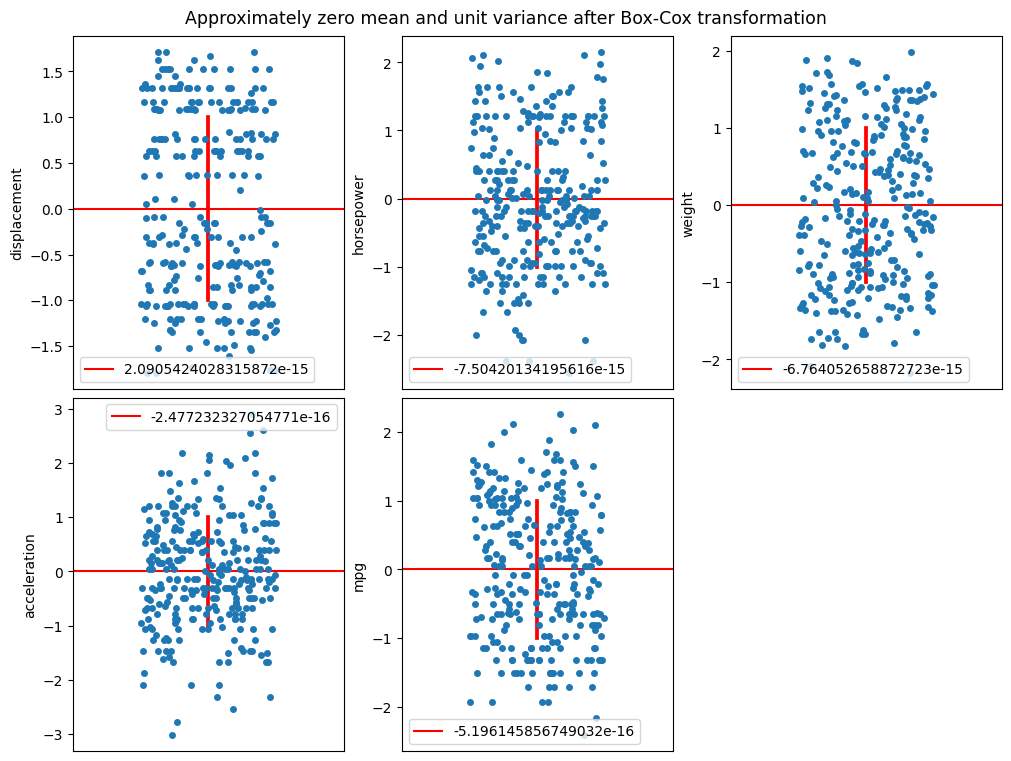

In [20]:
# transform numerical features in train set, and
# inspect variable magnitude after transformation
transformer = PowerTransformer(method="box-cox")

numerical_transformed = pd.DataFrame(
    data=transformer.fit_transform(X=numerical_train),
    columns=transformer.get_feature_names_out()
)
continuous_transformed = numerical_transformed.drop(columns=discrete_columns)

# create & setup plot figure
width, height = 10, 7.5
plt.figure(
    figsize=(width, height),
    layout="constrained"
)
suptitle_size = 12.5
plt.suptitle(
    t="Approximately zero mean and unit variance after Box-Cox transformation",
    size=suptitle_size
)

plot_continuous(
    data=continuous_transformed,
    estimator="mean",
    nrows=nrows,
    ncols=ncols
)

* *Metode Box-Cox digunakan sesuai temuan pada [Section 2: Visual Analysis](#visual-analysis); karena data [bernilai positif](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PowerTransformer.html), dan [performs better](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_map_data_to_normal.html#sphx-glr-auto-examples-preprocessing-plot-map-data-to-normal-py) than Yeo-Johnson*.
* Setelah melalui standarisasi, tiap variabel numerik dalam data memiliki `mean` yang mendekati nol. Serta `std` dalam satuan unit yang serupa antara `-1 - 1`.
* Proses ini juga meratakan order of the magnitude, sehingga nilai tiap variabel berada pada rentang nilai satuan —or within about a factor of 10 from each other.

#### One-Hot Encoding

* Most machine learning models operate on mathematical computations, requiring numbers, not text. Sehingga encoding diperlukan untuk mengubah data dalam bentuk teks seperti categorical features menjadi numerik.
* Teknik encoding yang digunakan kali ini adalah yang paling umum diterapkan, yakni [one-hot encoding](https://scikit-learn.org/stable/modules/preprocessing.html#encoding-categorical-features). One-hot encoding transforms each categorical features with $n$ possible values into $n$ binary features, with one of them 1, and all others 0.

In [21]:
# encode categorical features in dataset, and
# inspect categorical features after encoding
categorical_train = data_train.select_dtypes(include="category")
encoder = OneHotEncoder(sparse_output=False)

pd.DataFrame(
    data=encoder.fit_transform(X=categorical_train),
    columns=encoder.get_feature_names_out()
).sample(n=5)

,origin_1,origin_2,origin_3
153,0.0,1.0,0.0
46,1.0,0.0,0.0
63,0.0,0.0,1.0
48,1.0,0.0,0.0
159,1.0,0.0,0.0


DataFrame di atas menampilkan hasil dari encoding pada 5 sample baris dari data train:
* Satu categorical variable `origin` yang memiliki 3 label diubah menjadi 3 numerical variable terpisah `origin_1, origin_2, & origin_3`.
* Tiap variabel tersebut hanya memiliki 2 kemungkinan nilai di dalamnya yakni `0 & 1`; `0` menandakan suatu observasi bukan bagian dari variabel tersebut dan sebaliknya untuk nilai `1`.

---

## Section 3 | Data Modeling

### Modeling ETL

In [22]:
def modeling_etl(id, random_state):
    """Modeling ETL process for data preparation and transformation.
    
    This function performs an Extract, Transform, Load (ETL) process on the dataset identified by the given UCI repository ID.
    It cleans the data by dropping missing values and matching categories based on specified variables.
    The cleaned data is then split into training and testing features and targets.
    
    Args:
        id (int): The UCI repository identifier for the dataset to be processed.
        random_state (int): The random state to ensure reproducibility of the data split.
    
    Returns:
        tuple: A tuple containing:
            - train_features (DataFrame): The features for the training set.
            - test_features (DataFrame): The features for the testing set.
            - train_target (Series): The target variable for the training set.
            - test_target (Series): The target variable for the testing set.
    """
    data = data_etl(id=id)

    dropper = DropMissingData()
    matcher = MatchCategories(
        variables="origin",
        ignore_format=True
    )
    pipeline = make_pipeline(dropper, matcher)
    data_cleaned = pipeline.fit_transform(X=data)
    
    train_features, test_features, train_target, test_target = data_split(
        dataset=data_cleaned,
        random_state=random_state
    )

    return train_features, test_features, train_target, test_target

In [23]:
# extract, transform, and load data for modeling
X_train, X_test, y_train, y_test = modeling_etl(
    id=auto_mpg_id,
    random_state=RANDOM_STATE
)

### Modeling Benchmark

Data modeling dalam supervised learning dimulai dengan melakukan a simple sanity check which consists of comparing one’s estimator against simple rules of thumb.
* Library `sklearn` menyediakan [`DummyRegressor`](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyRegressor.html) which serves as a simple baseline to compare against other more complex regressors.
* This regressor in particular makes predictions —via `predict()` function— that ignore the input features.

In [24]:
# initialize, fit, and make prediction using dummy regressor
dummy = DummyRegressor(strategy="median")

dummy.fit(
    X=X_train,
    y=y_train
)

y_pred = dummy.predict(X=X_test)
y_pred

array([23., 23., 23., 23., 23., 23., 23., 23., 23., 23., 23., 23., 23.,
       23., 23., 23., 23., 23., 23., 23., 23., 23., 23., 23., 23., 23.,
       23., 23., 23., 23., 23., 23., 23., 23., 23., 23., 23., 23., 23.,
       23., 23., 23., 23., 23., 23., 23., 23., 23., 23., 23., 23., 23.,
       23., 23., 23., 23., 23., 23., 23., 23., 23., 23., 23., 23., 23.,
       23., 23., 23., 23., 23., 23., 23., 23., 23., 23., 23., 23., 23.,
       23., 23., 23., 23., 23., 23., 23., 23., 23., 23., 23., 23., 23.,
       23., 23., 23., 23., 23., 23., 23.])

* Array di atas adalah hasil prediksi dari `DummyRegressor` terhadap `X_test`, sehingga panjang dari array tersebut corresponds dengan jumlah data pada `X_test`.
* Dapat dilihat bahwasanya prediksi konstan `23.0` yang dilakukan oleh `DummyRegressor` serupa dengan nilai median dari target variabel `mpg` pada `X_train` yang telah ditemukan pada [Section 2: Visual Analysis](#visual-analysis).

### Evaluation Metric

The goal of training a model is to minimize the [loss](https://developers.google.com/machine-learning/crash-course/linear-regression/loss), reducing it to its lowest possible value.

In [ ]:
mse_dummy = mean_squared_error(
    y_true=y_test,
    y_pred=y_pred
)

pd.DataFrame(
    data=[mse_dummy],
    index=["Dummy"],
    columns=["MAE"]
)

,MAE
Dummy,50.518878


In [ ]:
def modeling_pipeline(alpha):
    """Creates a modeling pipeline for regression tasks with preprocessing and target transformation.
    
    This function constructs a machine learning pipeline that includes feature transformation for numerical features, 
    one-hot encoding for categorical features, and a Ridge regression model with a transformed target. 
    The pipeline is designed to handle both numerical and categorical data efficiently.
    
    Args:
        alpha (float): Regularization strength for the Ridge regression model. Must be a positive float.
    
    Returns:
        Pipeline: A scikit-learn pipeline object that includes preprocessing steps and a Ridge regression model with transformed target.
    """
    feature_transformer = PowerTransformer(method="box-cox")
    encoder = OneHotEncoder(sparse_output=False)
    preprocessor = make_column_transformer(
        (feature_transformer, make_column_selector(dtype_include="number")),
        (encoder, make_column_selector(dtype_include="category")),
        verbose_feature_names_out=False
    )

    regressor = Ridge(
        alpha=alpha,
        fit_intercept=False,
        random_state=RANDOM_STATE
    )
    target_transformer = PowerTransformer(method="box-cox")
    regressor = TransformedTargetRegressor(
        regressor=regressor,
        transformer=target_transformer
    )
    
    pipeline = make_pipeline(
        preprocessor,
        regressor
    )

    return pipeline

* [Pipeline](https://scikit-learn.org/stable/modules/compose.html#pipeline) untuk pemodelan dimulai dengan mengintegrasikan feature engineering sesuai tahapan [Section 2: Data Preprocessing](#data-preprocessing).

In [27]:
alpha = 1
estimator = modeling_pipeline(alpha=alpha)
estimator

,steps,"[('columntransformer', ...), ('transformedtargetregressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('powertransformer', ...), ('onehotencoder', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


In [28]:
param_name = "transformedtargetregressor__regressor__alpha"
param_range = np.logspace(start=-2, stop=2, num=5)
param_grid = {param_name: param_range}

scoring = make_scorer(score_func=mean_squared_error)
scoring.__name__ = 'Mean Squared Error'

cv = KFold(
    shuffle=True,
    random_state=RANDOM_STATE
)

search = GridSearchCV(
    estimator=estimator,
    param_grid=param_grid,
    scoring=scoring,
    cv=cv
)
search.fit(
    X=X_train,
    y=y_train
)

,estimator,Pipeline(step...'box-cox')))])
,param_grid,"{'transformedtargetregressor__regressor__alpha': array([1.e-02...e+01, 1.e+02])}"
,scoring,make_scorer(m...hod='predict')
,n_jobs,None
,refit,True
,cv,KFold(n_split... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('powertransformer', ...), ('onehotencoder', ...)]"


In [29]:
tuned_estimator = modeling_pipeline(alpha=search.best_params_.get(param_name))
tuned_estimator

,steps,"[('columntransformer', ...), ('transformedtargetregressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('powertransformer', ...), ('onehotencoder', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


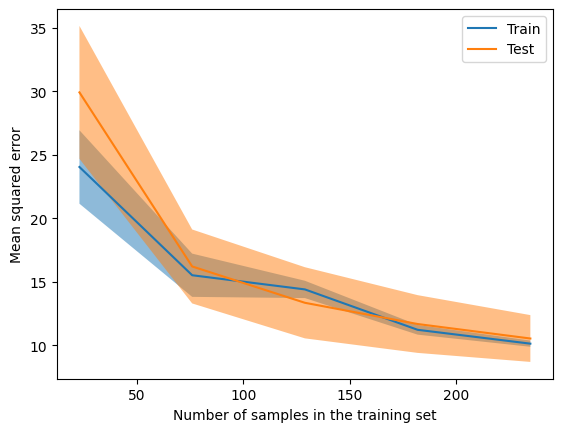

In [30]:
LearningCurveDisplay.from_estimator(
    estimator=tuned_estimator,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    random_state=RANDOM_STATE
)

plt.show()

In [31]:
def model_evaluation(y_true, y_pred, random_state):
    def detect_residual_outlier(target_true, target_prediction):
        residual = target_true - target_prediction
        mean_residual = residual.mean()
        std_residual = residual.std()

        z = (residual - mean_residual) / std_residual
        sigma = 3
        outlier = abs(z) > sigma

        return outlier

    is_outlier = detect_residual_outlier(
        target_true=y_true,
        target_prediction=y_pred
    )

    _, (ax_1, ax_2) = plt.subplots(
        nrows=1,
        ncols=2,
        figsize=(15, 5)
    )

    c = ['orange' if outlier else 'blue' for outlier in is_outlier]

    PredictionErrorDisplay.from_predictions(
        y_true=y_true,
        y_pred=y_pred,
        kind='actual_vs_predicted',
        random_state=random_state,
        ax=ax_1,
        scatter_kwargs={'c': c}
    )

    PredictionErrorDisplay.from_predictions(
        y_true=y_true,
        y_pred=y_pred,
        kind='residual_vs_predicted',
        random_state=random_state,
        ax=ax_2,
        scatter_kwargs={'c': c}
    )

    plt.show()

    return is_outlier

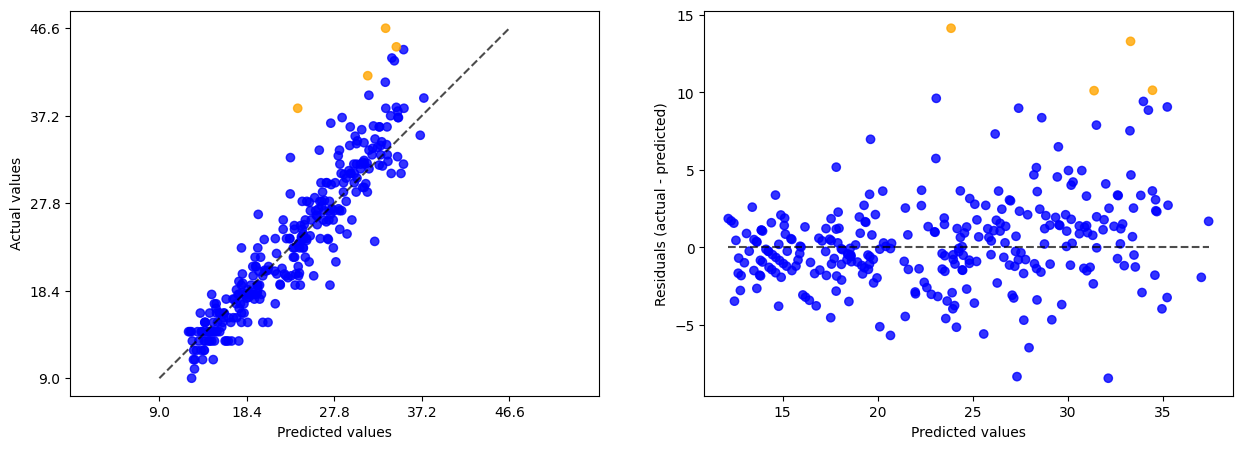

In [32]:
tuned_estimator.fit(
    X=X_train,
    y=y_train
)

y_pred_train = pd.Series(
    data=tuned_estimator.predict(X=X_train),
    index=y_train.index
)

_ = model_evaluation(
    y_true=y_train,
    y_pred=y_pred_train,
    random_state=RANDOM_STATE
)

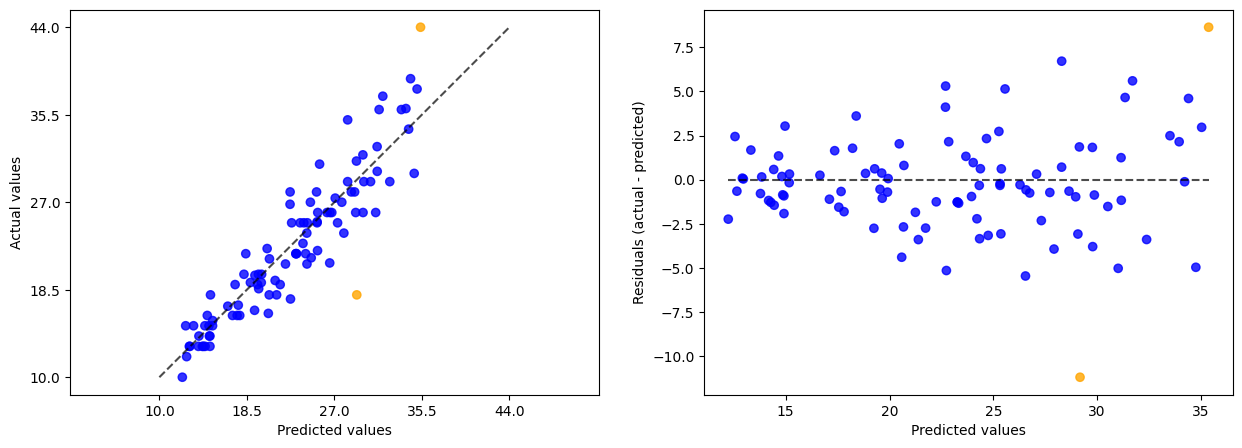

In [33]:
y_pred_test = pd.Series(
    data=tuned_estimator.predict(X=X_test),
    index=y_test.index
)

_ = model_evaluation(
    y_true=y_test,
    y_pred=y_pred_test,
    random_state=RANDOM_STATE
)

In [34]:
y_pred_test.to_numpy()

array([26.57644395, 24.75355889, 33.95283069, 26.28736588, 27.72305354,
       28.96782308, 12.91155319, 29.074707  , 19.54214955, 32.3845754 ,
       13.32160643, 21.73862635, 16.64795583, 28.29018077, 20.58721751,
       28.64786351, 19.62440253, 31.15380529, 27.08455828, 28.29283022,
       18.39529444, 35.3721957 , 34.21670291, 14.96710916, 29.78659452,
       25.38611103, 22.25187154, 17.10532783, 31.01529435, 24.21095901,
       15.168295  , 21.2468443 , 18.84439625, 29.77294148, 14.17661474,
       35.03578566, 14.85621011, 25.32159921, 14.44484202, 12.23227409,
       14.91630161, 27.92453176, 33.51066848, 26.752356  , 14.91425705,
       12.95952176, 17.35832837, 31.7060141 , 24.3396718 , 30.5171628 ,
       13.84364987, 24.32469457, 22.7020888 , 31.34865672, 23.32991879,
       17.55687444, 18.21948633, 19.93539555, 22.85081077, 24.03216126,
       12.64889522, 20.46964114, 22.69539293, 23.95105852, 26.54906997,
       27.31332116, 25.32476052, 29.8675207 , 19.28443178, 12.55

In [35]:
mse_ridge = mean_squared_error(
    y_true=y_test,
    y_pred=y_pred_test
)
pd.DataFrame(
    data=[mse_dummy, mse_ridge, 1 - (mse_ridge / mse_dummy)],
    index=["Dummy", "Ridge", "Δ"],
    columns=["MAE"]
)

,MAE
Dummy,50.518878
Ridge,7.938780
Δ,0.842855


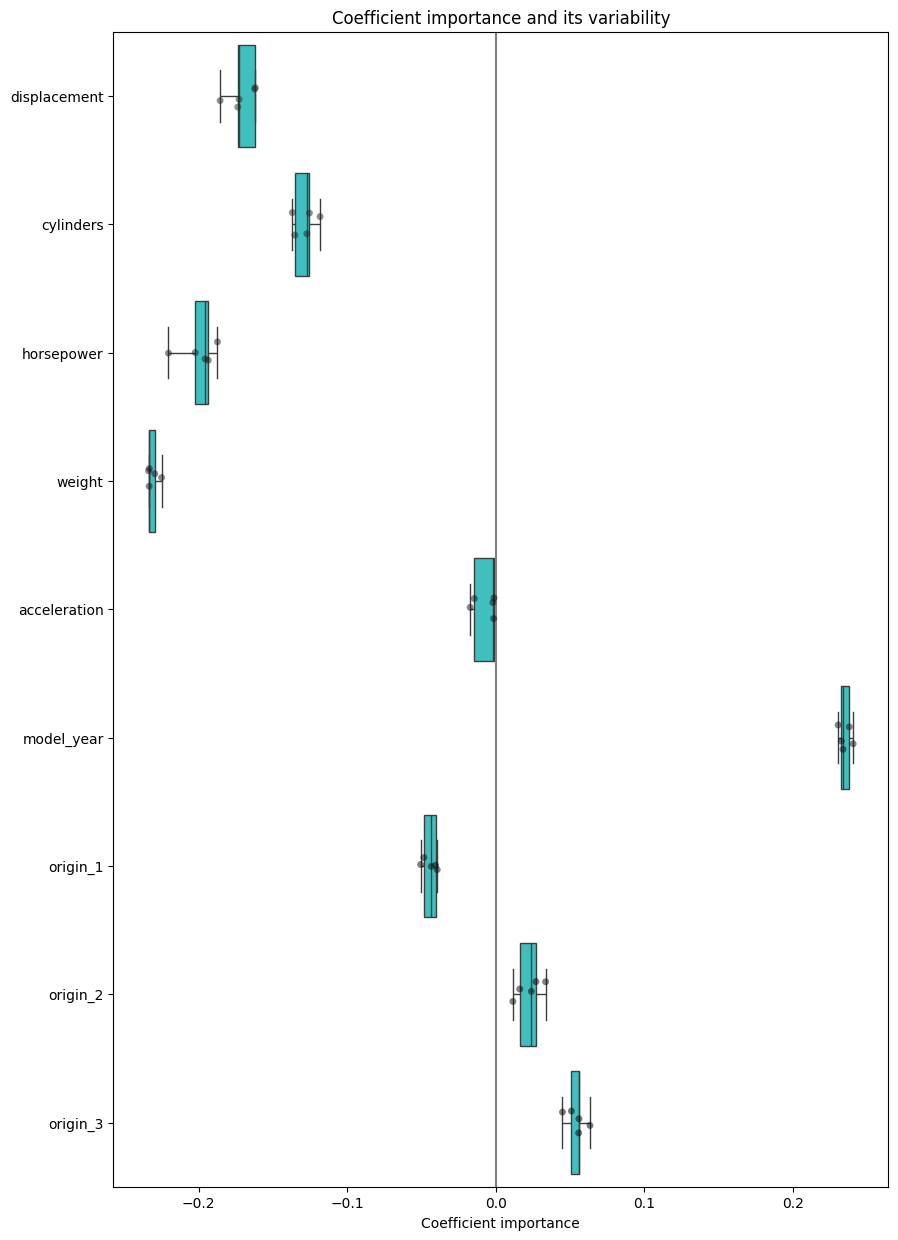

In [36]:
from sklearn.model_selection import cross_validate

cv_estimator = cross_validate(
    estimator=tuned_estimator,
    X=X_train,
    y=y_train,
    scoring=scoring,
    cv=cv,
    return_estimator=True
)

feature_names = tuned_estimator['columntransformer'].get_feature_names_out()
coefs = pd.DataFrame(
    data=[estimator['transformedtargetregressor'].regressor_.coef_ for estimator in cv_estimator['estimator']],
    columns=feature_names
)

plt.figure(figsize=(10, 15))
sns.stripplot(data=coefs, orient="h", palette="dark:k", alpha=0.5)
sns.boxplot(data=coefs, orient="h", color="cyan", saturation=0.5, whis=10)
plt.axvline(x=0, color=".5")
plt.xlabel("Coefficient importance")
plt.title("Coefficient importance and its variability")
plt.show()

---

## Reference

* Quinlan, R. (1993). Combining Instance-Based and Model-Based Learning. *In Proceedings on the Tenth International Conference of Machine Learning*, 236-243, University of Massachusetts, Amherst: Morgan Kaufmann.
* Little, R. J. A. (1988). A Test of Missing Completely at Random for Multivariate Data with Missing Values. *Journal of the American Statistical Association, 83*(404), 1198–1202. https://doi.org/10.1080/01621459.1988.10478722
* Tukey, J. W. (1977). *Exploratory Data Analysis*. Reading, Massachusetts: Addison-Wesley.